# KryptoNet-40 adaptation results (member D)

Builds the adaptation table and figures for the report from `results/adapt_runs.csv`, which `adapt.py`
writes. Run the experiments first, e.g.

```
python adapt.py --method zero-shot
python adapt.py --method linear-probe --seed 42      # and seeds 123, 2026
python adapt.py --method lora --rank 4 --seed 42     # ranks 1, 2, 4, 8; seeds 42, 123, 2026
```

**Which runs are reported.** Only runs recorded against a clean commit (no `-dirty` suffix). If the same
configuration and training seed was run more than once, the latest run is used. All numbers here are
**validation** accuracy on the shared 40-adapt split (800 rows); the local test set is not read.

The last section checks the LoRA operation counts from the report against PyTorch's own FLOP counter.

In [1]:
import csv
import json
import math
from collections import defaultdict
from pathlib import Path
from statistics import mean, stdev

import matplotlib.pyplot as plt

ROOT = Path.cwd()
RUNS = ROOT / "results" / "adapt_runs.csv"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
N_VAL = 800

plt.rcParams.update({
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8a85", "axes.linewidth": 0.8,
    "xtick.color": "#5c5c57", "ytick.color": "#5c5c57", "axes.labelcolor": "#2b2b28",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "savefig.bbox": "tight", "savefig.dpi": 300,
})
GRAY, INK = "#8a8a85", "#2b2b28"
LORA_BLUES = {1: "#86b6ef", 2: "#5598e7", 4: "#2a78d6", 8: "#184f95", 16: "#0d366b"}

## 1. Select the reported runs

In [2]:
def key(row):
    config = json.loads(row["configuration"])
    return (row["method"], config.get("rank"), config.get("alpha"), config.get("head"), config.get("lr"), int(row["training_seed"]))


with RUNS.open(newline="", encoding="utf-8") as source:
    rows = list(csv.DictReader(source))

clean = [r for r in rows if not r["code_commit"].endswith("-dirty") and r["code_commit"] != "unknown"]
latest = {}
for row in sorted(clean, key=lambda r: r["run_id"]):  # run_id starts with a UTC timestamp
    latest[key(row)] = row
reported = sorted(latest.values(), key=lambda r: (r["method"], json.loads(r["configuration"]).get("rank") or 0, int(r["training_seed"])))

print(f"{len(rows)} recorded runs, {len(rows) - len(clean)} excluded as uncommitted, "
      f"{len(clean) - len(reported)} superseded repeats, {len(reported)} reported\n")
print(f"{'run_id':40} {'commit':8} {'val acc':>8} {'params':>8} {'epoch':>6}")
for r in reported:
    print(f"{r['run_id']:40} {r['code_commit'][:7]:8} {float(r['validation_accuracy']):8.4f} {int(r['trainable_params']):8d} {r['best_epoch']:>6}")

21 recorded runs, 5 excluded as uncommitted, 0 superseded repeats, 16 reported

run_id                                   commit    val acc   params  epoch
20261110T151906Z_linear-probe_s42        e1169a8    0.5212      513     33
20261110T150827Z_linear-probe_s123       e1169a8    0.5275      513     55
20261110T150845Z_linear-probe_s2026      e1169a8    0.5238      513     18
20261110T152026Z_lora_r1_s42             e1169a8    0.9625     4137     18
20261110T152056Z_lora_r1_s123            e1169a8    0.9637     4137     18
20261110T152128Z_lora_r1_s2026           e1169a8    0.9637     4137     26
20261110T145051Z_lora_r2_s42             9076266    0.9650     7761     13
20261110T145112Z_lora_r2_s123            9076266    0.9625     7761     20
20261110T145133Z_lora_r2_s2026           9076266    0.9425     7761     37
20261110T145152Z_lora_r4_s42             9076266    0.9650    15009     14
20261110T145212Z_lora_r4_s123            9076266    0.9613    15009     13
20261110T145231Z_lor

## 2. Summary table

In [3]:
def label(row):
    if row["method"] == "lora":
        return f"LoRA r={json.loads(row['configuration'])['rank']}"
    return {"zero-shot": "Zero-shot", "linear-probe": "Linear probe"}[row["method"]]


groups = defaultdict(list)
for row in reported:
    groups[label(row)].append(row)

order = ["Zero-shot", "Linear probe"] + sorted((g for g in groups if g.startswith("LoRA")), key=lambda g: int(g.split("=")[1]))
summary = []
for name in order:
    runs = groups[name]
    acc = [100 * float(r["validation_accuracy"]) for r in runs]
    metrics = [json.loads(r["validation_metrics"]) for r in runs]
    summary.append({
        "method": name,
        "params": int(runs[0]["trainable_params"]),
        "seeds": len(runs),
        "acc_mean": mean(acc),
        "acc_sd": stdev(acc) if len(acc) > 1 else None,
        "f1": mean(m["f1"] for m in metrics),
        "auc": mean(m["roc_auc"] for m in metrics),
        "seconds": mean(float(r["elapsed_seconds"]) for r in runs),
        "epoch": [int(r["best_epoch"]) for r in runs],
    })

print(f"{'Method':14} {'Params':>8} {'Seeds':>5} {'Val acc (%)':>14} {'F1':>6} {'AUC':>6} {'Time (s)':>9}  Best epochs")
for s in summary:
    spread = f"{s['acc_mean']:.1f} ± {s['acc_sd']:.1f}" if s["acc_sd"] is not None else f"{s['acc_mean']:.1f}"
    print(f"{s['method']:14} {s['params']:8d} {s['seeds']:5d} {spread:>14} {s['f1']:6.3f} {s['auc']:6.3f} {s['seconds']:9.1f}  {s['epoch']}")

# Sampling uncertainty of a single accuracy estimate on the 800-row validation set.
p = summary[-1]["acc_mean"] / 100
print(f"\nBinomial standard error at {100 * p:.1f}% with n={N_VAL}: ±{100 * math.sqrt(p * (1 - p) / N_VAL):.2f} points;"
      f" one validation example = {100 / N_VAL:.3f} points")

Method           Params Seeds    Val acc (%)     F1    AUC  Time (s)  Best epochs
Zero-shot             0     1           49.0  0.487  0.501       0.0  [0]
Linear probe        513     3     52.4 ± 0.3  0.584  0.504      15.0  [33, 55, 18]
LoRA r=1           4137     3     96.3 ± 0.1  0.964  0.974      24.1  [18, 18, 26]
LoRA r=2           7761     3     95.7 ± 1.2  0.958  0.971      17.9  [13, 20, 37]
LoRA r=4          15009     3     96.3 ± 0.2  0.964  0.975      15.4  [14, 13, 14]
LoRA r=8          29505     3     96.2 ± 0.2  0.963  0.975      16.6  [13, 13, 14]

Binomial standard error at 96.2% with n=800: ±0.68 points; one validation example = 0.125 points


In [4]:
# LaTeX rows for the report table (mean ± sample standard deviation over training seeds).
for s in summary:
    acc = f"${s['acc_mean']:.1f} \\pm {s['acc_sd']:.1f}$" if s["acc_sd"] is not None else f"${s['acc_mean']:.1f}$"
    print(f"{s['method']} & {s['params']:,} & {acc} & {s['f1']:.3f} & {s['seconds']:.0f} \\\\".replace(",", "{,}"))

Zero-shot & 0 & $49.0$ & 0.487 & 0 \\
Linear probe & 513 & $52.4 \pm 0.3$ & 0.584 & 15 \\
LoRA r=1 & 4{,}137 & $96.3 \pm 0.1$ & 0.964 & 24 \\
LoRA r=2 & 7{,}761 & $95.7 \pm 1.2$ & 0.958 & 18 \\
LoRA r=4 & 15{,}009 & $96.3 \pm 0.2$ & 0.964 & 15 \\
LoRA r=8 & 29{,}505 & $96.2 \pm 0.2$ & 0.963 & 17 \\


## 3. Figure: accuracy against trainable parameters

Small open markers are individual training seeds; filled markers are the mean. Zero-shot trains no parameters,
so it is drawn as a reference line rather than a point on the logarithmic axis.

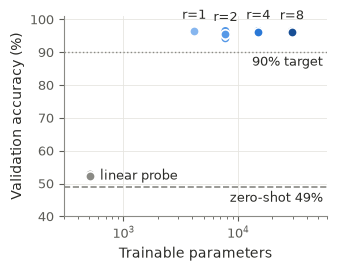

In [5]:
fig, ax = plt.subplots(figsize=(3.4, 2.6))
zero = next(s for s in summary if s["method"] == "Zero-shot")
ax.axhline(zero["acc_mean"], color=GRAY, lw=1.2, ls="--", zorder=1)
ax.text(55_000, zero["acc_mean"] - 1.2, f"zero-shot {zero['acc_mean']:.0f}%", color=INK, fontsize=9, ha="right", va="top")
ax.axhline(90, color=GRAY, lw=1.0, ls=":", zorder=1)
ax.text(55_000, 90 - 1.2, "90% target", color=INK, fontsize=9, ha="right", va="top")

for s in summary:
    if s["method"] == "Zero-shot":
        continue
    colour = GRAY if s["method"] == "Linear probe" else LORA_BLUES.get(int(s["method"].split("=")[1]), "#2a78d6")
    accs = [100 * float(r["validation_accuracy"]) for r in groups[s["method"]]]
    ax.scatter([s["params"]] * len(accs), accs, s=22, facecolors="none", edgecolors=colour, linewidths=1.0, zorder=3)
    ax.scatter([s["params"]], [s["acc_mean"]], s=46, color=colour, edgecolors="white", linewidths=1.2, zorder=4)
    name = "linear probe" if s["method"] == "Linear probe" else s["method"].replace("LoRA ", "")
    if s["method"] == "Linear probe":
        ax.annotate(name, (s["params"], s["acc_mean"]), xytext=(7, 0), textcoords="offset points",
                    ha="left", va="center", fontsize=9, color=INK)
    else:
        ax.annotate(name, (s["params"], s["acc_mean"]), xytext=(0, 7), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color=INK)

ax.set_xscale("log")
ax.set_xlim(300, 60_000)
ax.set_ylim(40, 101)
ax.set_xlabel("Trainable parameters")
ax.set_ylabel("Validation accuracy (%)")
fig.savefig(FIGURES / "adapt_accuracy_vs_params.pdf")
fig.savefig(FIGURES / "adapt_accuracy_vs_params.png")
plt.show()

## 4. Figure: validation accuracy during training (training seed 42)

The best epoch selected by early stopping is marked. LoRA stays near chance for a few epochs and then
rises sharply as the hidden-layer representation changes; the linear probe never leaves chance.

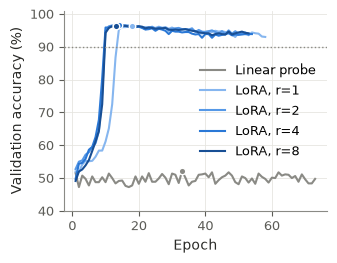

In [6]:
def history(row):
    path = next(p for p in row["output_paths"].split(";") if p.endswith("history.json"))
    return json.loads((ROOT / path.replace("\\", "/")).read_text(encoding="utf-8"))  # paths may be Windows-style


curves = [r for r in reported if r["method"] != "zero-shot" and int(r["training_seed"]) == 42]
fig, ax = plt.subplots(figsize=(3.4, 2.6))
for row in sorted(curves, key=lambda r: (r["method"] != "linear-probe", json.loads(r["configuration"]).get("rank") or 0)):
    h = history(row)
    rank = json.loads(row["configuration"]).get("rank")
    colour = GRAY if row["method"] == "linear-probe" else LORA_BLUES.get(rank, "#2a78d6")
    epochs = [e["epoch"] for e in h]
    acc = [100 * e["val_acc"] for e in h]
    ax.plot(epochs, acc, color=colour, lw=1.5, label=label(row).replace("LoRA ", "LoRA, "))
    best = int(row["best_epoch"])
    ax.scatter([best], [100 * h[best - 1]["val_acc"]], s=22, color=colour, edgecolors="white", linewidths=1.0, zorder=4)

ax.axhline(90, color=GRAY, lw=1.0, ls=":")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.set_ylim(40, 101)
ax.legend(frameon=False, loc="center right")
fig.savefig(FIGURES / "adapt_training_curves.pdf")
fig.savefig(FIGURES / "adapt_training_curves.png")
plt.show()

## 5. Check the operation counts against PyTorch

The report counts an $n\times m$ by $m\times k$ product as $nmk$ operations and ignores bias additions,
activations and the scalar $\alpha/r$. `torch.utils.flop_counter` counts the same matrix products as $2nmk$
(a multiply and an add), so its totals are halved below. For one training step on a batch of $N$ inputs:

* **Full fine-tuning** of KryptoNet-40: every weight gradient plus the input gradient of every layer above the first.
* **LoRA** on the four hidden layers with the pretrained head trainable: no gradient for any frozen $W$, but
  $W^\top G$ is still computed for hidden layers 2–4 and the head, because LoRA factors sit below them.

In [7]:
import torch
import torch.nn.functional as F
from torch.utils.flop_counter import FlopCounterMode

from kryptonet import load_kryptonet
from lora import apply_lora

DIMS = [(40, 512), (512, 512), (512, 512), (512, 512), (512, 1)]  # (d_in, d_out) per layer; the last is the head


def full_ops(N):
    forward = sum(i * o * N for i, o in DIMS)
    weight_grads = sum(o * N * i for i, o in DIMS)
    input_grads = sum(i * o * N for i, o in DIMS[1:])  # no gradient is needed for the data
    return forward + weight_grads + input_grads


def lora_ops(N, r, train_head=True):
    hidden, (hi, ho) = DIMS[:4], DIMS[4]
    forward = sum(i * o * N + r * i * N + o * r * N for i, o in hidden) + hi * ho * N
    head = (ho * N * hi if train_head else 0) + hi * ho * N      # head weight gradient; W^T G into layer 4
    first = r * 512 * N + 512 * N * r + r * N * 40               # layer 1: G_Z = B^T G, dB, dA; no input gradient
    upper = 3 * (512 * 512 * N + r * 512 * N + 512 * N * r + r * N * 512 + 512 * r * N)  # + W^T G and A^T G_Z
    return forward + head + first + upper


def measured_ops(model, N, seed=0):
    torch.manual_seed(seed)
    x, y = torch.randn(N, 40), torch.randint(0, 2, (N,)).float()
    counter = FlopCounterMode(display=False)
    with counter:
        loss = F.binary_cross_entropy_with_logits(model(x).squeeze(1), y)
        loss.backward()
    model.zero_grad(set_to_none=True)
    return counter.get_total_flops() // 2


N = 128
base = load_kryptonet(ROOT / "kryptonet40.pt")
check = [("Full fine-tuning", full_ops(N), measured_ops(base.train(), N))]
for r in (1, 2, 4, 8):
    check.append((f"LoRA r={r}", lora_ops(N, r), measured_ops(apply_lora(base, r, 8.0).train(), N)))

full = check[0][1]
print(f"Operations per training step, N={N}\n")
print(f"{'Method':18} {'formula':>13} {'PyTorch':>13} {'per input':>11} {'vs full':>8}")
for name, formula, measured in check:
    print(f"{name:18} {formula:13,d} {measured:13,d} {formula // N:11,d} {formula / full:8.3f}")
    assert formula == measured, f"{name}: formula {formula} != measured {measured}"
print("\nAll formula counts match PyTorch's counter.")

Operations per training step, N=128

Method                   formula       PyTorch   per input  vs full
Full fine-tuning     307,429,376   307,429,376   2,401,792    1.000
LoRA r=1             205,531,136   205,531,136   1,605,712    0.669
LoRA r=2             206,917,632   206,917,632   1,616,544    0.673
LoRA r=4             209,690,624   209,690,624   1,638,208    0.682
LoRA r=8             215,236,608   215,236,608   1,681,536    0.700

All formula counts match PyTorch's counter.
